# Diagnóstico: as notas de outras áreas influenciam a nota de Matemática? (dataset 6)

> **Atenção: isto NÃO faz parte da solução.** O enunciado do projeto **proíbe** usar notas de outras áreas, da redação, presença, respostas ou gabarito como entrada, porque descrevem a própria prova e não o perfil do participante. Este notebook existe só para **medir o tamanho do vazamento** e mostrar que o limite de R² ≈ 0,35 dos notebooks anteriores é de informação, e não de modelo. O resultado não entra na solução final, no teste final nem no artigo como método, apenas como contraste.

**Como é feito:** o **dataset 6** é o `dataset_3_escola_features` (45 colunas) mais as notas de Ciências da Natureza (`NU_NOTA_CN`, mesmo dia da prova de Matemática), Ciências Humanas (`NU_NOTA_CH`), Linguagens (`NU_NOTA_LC`) e Redação (`NU_NOTA_REDACAO`), esses três do primeiro dia. Quem não fez uma prova tem nota ausente: a ausência vira **0** e ganha uma coluna indicadora `*_AUSENTE` (sem nenhum nulo, como nos outros datasets). Só a validação cruzada de 3 dobras no desenvolvimento é usada; **o teste não é aberto**. Mesmas dobras, semente 42.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import PredefinedSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ALVO, PROC, TAB, FIG = "NU_NOTA_MT", Path("../dados/processed"), Path("../resultados/tabelas"), Path("../resultados/figuras")
NOTAS = {"NU_NOTA_CN": "Ciências da Natureza (mesmo dia)", "NU_NOTA_CH": "Ciências Humanas (dia 1)",
         "NU_NOTA_LC": "Linguagens e Códigos (dia 1)", "NU_NOTA_REDACAO": "Redação (dia 1)"}

ids = pd.read_csv(PROC / "ids_elegiveis.csv")["NU_INSCRICAO"]
em_dev = ids.isin(pd.read_csv("../dados/splits/desenvolvimento_ids.csv")["NU_INSCRICAO"]).to_numpy()
dobras = PredefinedSplit(pd.read_csv("../dados/splits/dobras_cv.csv")["dobra"].to_numpy())

base = pd.read_csv(PROC / "dataset_3_escola_features.csv")
bruto = pd.read_csv("../dados/raw/DADOS/MICRODADOS_ENEM_2023.csv", sep=";", encoding="latin1",
                    usecols=["NU_INSCRICAO"] + list(NOTAS)).set_index("NU_INSCRICAO").loc[ids].reset_index(drop=True)
assert len(bruto) == len(base) == len(ids)

# dataset 6: base + 4 notas (ausente = 0) + 4 indicadoras de ausência; o alvo fica por último
d6 = base.drop(columns=ALVO).copy()
for c in NOTAS:
    d6[c] = bruto[c].fillna(0).astype("float32")
    d6[c.replace("NU_NOTA_", "AUSENTE_")] = bruto[c].isna().astype("int8")
d6[ALVO] = base[ALVO].values
assert d6.isna().sum().sum() == 0
d6.to_csv(PROC / "dataset_6_notas_outras_areas.csv", index=False)
print("dataset_6_notas_outras_areas:", d6.shape[0], "linhas,", d6.shape[1] - 1, "features (45 do dataset 3 + 4 notas + 4 indicadoras)")

X6, y = d6[em_dev].reset_index(drop=True).drop(columns=ALVO), base.loc[em_dev, ALVO].reset_index(drop=True)
print("Participantes do desenvolvimento sem cada nota:", {c.replace('NU_NOTA_', ''): f"{bruto.loc[em_dev, c].isna().mean():.1%}" for c in NOTAS})

dataset_6_notas_outras_areas: 2692427 linhas, 53 features (45 do dataset 3 + 4 notas + 4 indicadoras)
Participantes do desenvolvimento sem cada nota: {'CN': '0.0%', 'CH': '0.5%', 'LC': '0.5%', 'REDACAO': '0.5%'}


## Quanto cada nota se parece com a de Matemática (só desenvolvimento)

Correlação de Pearson entre cada nota e a de Matemática, entre quem tem as duas.

In [2]:
dev = bruto[em_dev].assign(MT=y.values)
corr = pd.DataFrame({NOTAS[c]: {"pessoas com as duas notas": int(dev[c].notna().sum()),
                                  "correlação (Pearson) com Matemática": dev[[c, "MT"]].dropna().corr().iloc[0, 1]} for c in NOTAS}).T
corr

,pessoas com as duas notas,correlação (Pearson) com Matemática
Ciências da Natureza (mesmo dia),2153941.0,0.713351
Ciências Humanas (dia 1),2142500.0,0.625519
Linguagens e Códigos (dia 1),2142500.0,0.616697
Redação (dia 1),2142500.0,0.498755


## Spearman do dataset 6

O mesmo critério dos outros datasets (correlação de ranking, limite de redundância |ρ| > 0,7), agora com as notas de outras áreas. Calculado **só no desenvolvimento** (2.153.941 participantes). As colunas `AUSENTE_*` (0/1) indicam quem não fez cada prova.

Colunas constantes no desenvolvimento (Spearman indefinido, fora dos gráficos): ['AUSENTE_CN']
Spearman de cada feature com a nota de Matemática (as 12 maiores em módulo):
NU_NOTA_CH         0.656
NU_NOTA_LC         0.643
NU_NOTA_CN         0.643
NU_NOTA_REDACAO    0.527
Q006               0.457
Q024               0.409
Q003               0.349
Q002               0.347
Q004               0.346
Q010               0.339
Q008               0.339
Q001               0.332


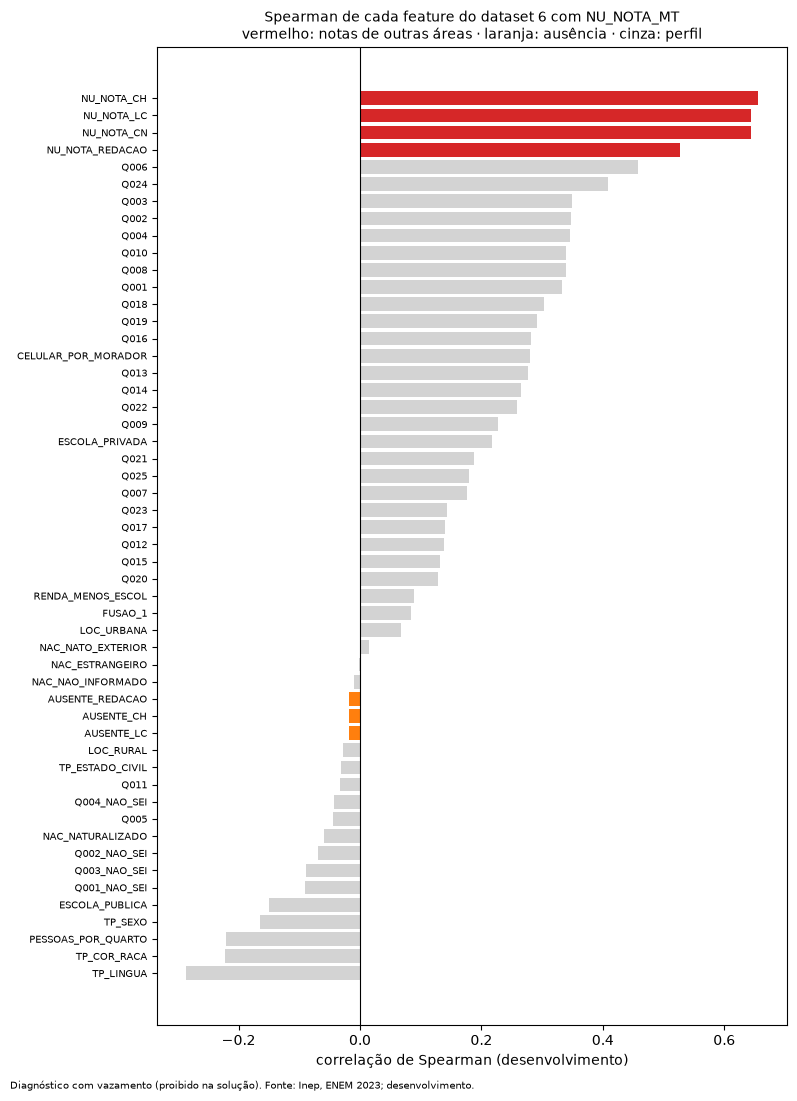

In [3]:
sp = d6[em_dev].rank().corr()
sp.to_csv(TAB / "diagnostico_dataset6_spearman_matriz.csv")
constantes = sp[ALVO].index[sp[ALVO].isna()].tolist()
print("Colunas constantes no desenvolvimento (Spearman indefinido, fora dos gráficos):", constantes)
alvo_sp = sp[ALVO].drop(ALVO).dropna().sort_values()
alvo_sp.rename("spearman_com_a_nota").to_csv(TAB / "diagnostico_dataset6_spearman_com_a_nota.csv")
print("Spearman de cada feature com a nota de Matemática (as 12 maiores em módulo):")
print(alvo_sp.reindex(alvo_sp.abs().sort_values(ascending=False).index).head(12).round(3).to_string())

cor = ["tab:red" if f in NOTAS else "tab:orange" if f.startswith("AUSENTE_") else "lightgray" for f in alvo_sp.index]
fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(alvo_sp.index, alvo_sp.values, color=cor)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Spearman de cada feature do dataset 6 com NU_NOTA_MT\nvermelho: notas de outras áreas · laranja: ausência · cinza: perfil", fontsize=10)
ax.set_xlabel("correlação de Spearman (desenvolvimento)")
ax.tick_params(axis="y", labelsize=7)
fig.text(0.01, 0.005, "Diagnóstico com vazamento (proibido na solução). Fonte: Inep, ENEM 2023; desenvolvimento.", fontsize=7)
plt.tight_layout(rect=(0, 0.01, 1, 1))
plt.savefig(FIG / "diagnostico_dataset6_spearman.png", dpi=150)
plt.show()

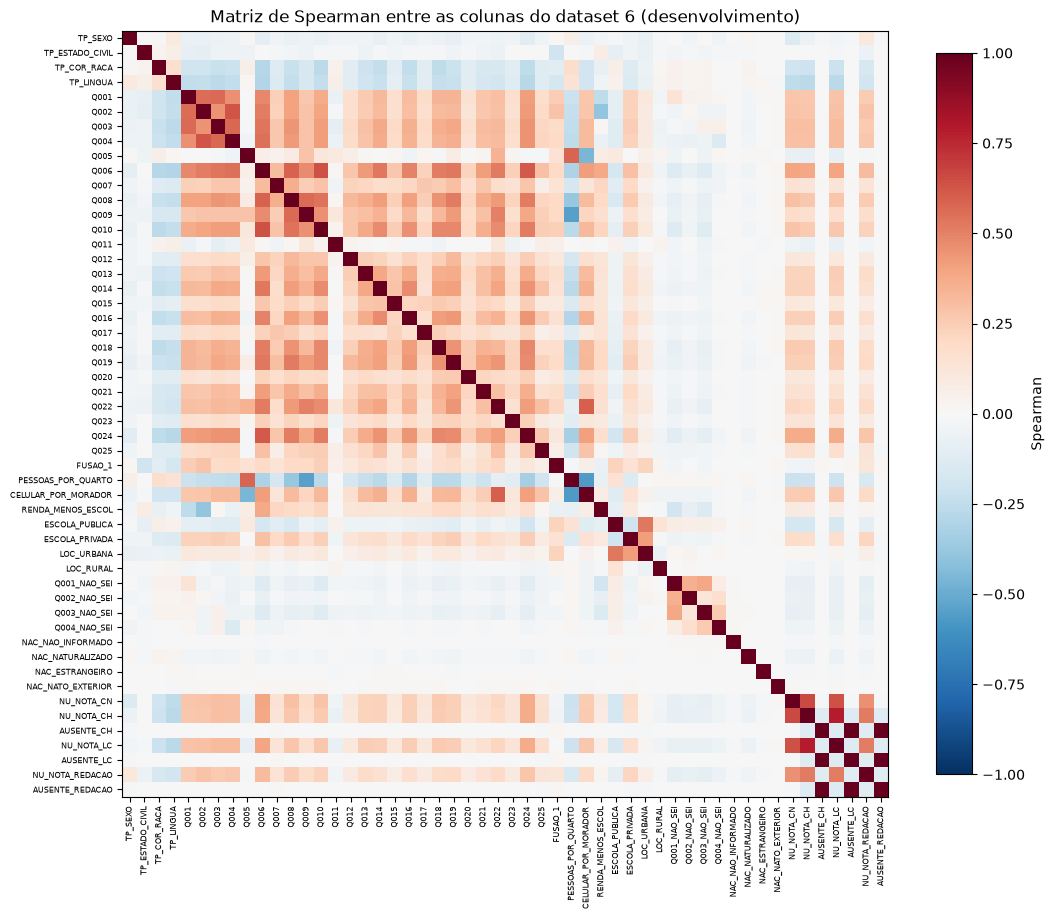

Pares com |Spearman| > 0,7: 4
  coluna_1            coluna_2  spearman
AUSENTE_LC     AUSENTE_REDACAO     1.000
AUSENTE_CH     AUSENTE_REDACAO     1.000
AUSENTE_CH          AUSENTE_LC     1.000
NU_NOTA_CH          NU_NOTA_LC     0.788
NU_NOTA_CN          NU_NOTA_CH     0.657
      Q006                Q010     0.640
NU_NOTA_CN          NU_NOTA_LC     0.636
      Q002                Q004     0.628
      Q006                Q024     0.615
      Q022 CELULAR_POR_MORADOR     0.595

Spearman entre as próprias notas:
  coluna_1        coluna_2  spearman
NU_NOTA_CN      NU_NOTA_CH     0.657
NU_NOTA_CN      NU_NOTA_LC     0.636
NU_NOTA_CN NU_NOTA_REDACAO     0.457
NU_NOTA_CH      NU_NOTA_LC     0.788
NU_NOTA_CH NU_NOTA_REDACAO     0.516
NU_NOTA_LC NU_NOTA_REDACAO     0.513


In [4]:
# matriz de Spearman entre as colunas e pares redundantes (|rho| > 0,7)
m = sp.drop(index=ALVO, columns=ALVO).dropna(how="all").dropna(axis=1, how="all")
fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(m)), m.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(m)), m.index, fontsize=6)
plt.colorbar(im, ax=ax, shrink=0.8, label="Spearman")
ax.set_title("Matriz de Spearman entre as colunas do dataset 6 (desenvolvimento)")
plt.tight_layout()
plt.savefig(FIG / "diagnostico_dataset6_spearman_matriz.png", dpi=150)
plt.show()

tri = m.where(np.triu(np.ones(m.shape, dtype=bool), k=1)).stack().dropna().rename("spearman").reset_index()
tri.columns = ["coluna_1", "coluna_2", "spearman"]
altos = tri.reindex(tri["spearman"].abs().sort_values(ascending=False).index)
print(f"Pares com |Spearman| > 0,7: {int((tri['spearman'].abs() > 0.7).sum())}")
print(altos.head(10).round(3).to_string(index=False))
notas_entre = tri[tri.coluna_1.isin(NOTAS) & tri.coluna_2.isin(NOTAS)]
print("\nSpearman entre as próprias notas:")
print(notas_entre.round(3).to_string(index=False))

## Validação cruzada: com e sem as notas

Gradient Boosting de configuração inicial (o mesmo das comparações do notebook 04) e regressão linear padronizada. Variantes de entrada: só o perfil (45 colunas); + a nota do **mesmo dia** da prova de Matemática (CN); + as 3 do **primeiro dia** (CH, LC e Redação); + as quatro.

In [5]:
def hgb():
    return HistGradientBoostingRegressor(learning_rate=0.1, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200,
                                         early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, random_state=42)


def cv(modelo, cols):
    linhas = []
    for tr, va in dobras.split():
        t0 = time.time()
        m = clone(modelo).fit(X6.iloc[tr][cols], y.iloc[tr])
        p = m.predict(X6.iloc[va][cols])
        linhas.append(dict(RMSE=mean_squared_error(y.iloc[va], p) ** 0.5, MAE=mean_absolute_error(y.iloc[va], p), R2=r2_score(y.iloc[va], p), tempo_s=time.time() - t0))
    return pd.DataFrame(linhas)


BASE = list(base.drop(columns=ALVO).columns)
aus = lambda *ns: [n.replace("NU_NOTA_", "AUSENTE_") for n in ns]
VARIANTES = {
    "só o perfil (45 colunas)": BASE,
    "+ Natureza (mesmo dia)": BASE + ["NU_NOTA_CN"] + aus("NU_NOTA_CN"),
    "+ Humanas, Linguagens e Redação (dia 1)": BASE + ["NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_REDACAO"] + aus("NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_REDACAO"),
    "+ as quatro notas": BASE + list(NOTAS) + aus(*NOTAS),
}
linhas = []
for nome, cols in VARIANTES.items():
    for modelo_nome, modelo in [("Gradient Boosting", hgb()), ("Regressão linear", make_pipeline(StandardScaler(), LinearRegression()))]:
        d = cv(modelo, cols)
        linhas.append({"entrada": nome, "modelo": modelo_nome, "colunas": len(cols), "RMSE": d.RMSE.mean(), "RMSE_desvio": d.RMSE.std(),
                       "MAE": d.MAE.mean(), "R2": d.R2.mean(), "tempo_s": d.tempo_s.mean()})
        print(f"{nome:<44} {modelo_nome:<18} RMSE {d.RMSE.mean():7.3f} ± {d.RMSE.std():.3f} | R² {d.R2.mean():.3f}", flush=True)
res = pd.DataFrame(linhas)
res.to_csv(TAB / "diagnostico_dataset6_notas_outras_areas.csv", index=False)
res.round(3)

só o perfil (45 colunas)                     Gradient Boosting  RMSE 107.048 ± 0.196 | R² 0.339


só o perfil (45 colunas)                     Regressão linear   RMSE 110.378 ± 0.190 | R² 0.297


+ Natureza (mesmo dia)                       Gradient Boosting  RMSE  82.826 ± 0.058 | R² 0.604


+ Natureza (mesmo dia)                       Regressão linear   RMSE  86.052 ± 0.093 | R² 0.573


+ Humanas, Linguagens e Redação (dia 1)      Gradient Boosting  RMSE  85.961 ± 0.228 | R² 0.574


+ Humanas, Linguagens e Redação (dia 1)      Regressão linear   RMSE  89.686 ± 0.179 | R² 0.536


+ as quatro notas                            Gradient Boosting  RMSE  74.426 ± 0.032 | R² 0.680


+ as quatro notas                            Regressão linear   RMSE  79.632 ± 0.062 | R² 0.634


,entrada,modelo,colunas,RMSE,RMSE_desvio,MAE,R2,tempo_s
0,só o perfil (45 colunas),Gradient Boosting,45,107.048,0.196,83.159,0.339,18.302
1,só o perfil (45 colunas),Regressão linear,45,110.378,0.190,86.234,0.297,0.920
2,+ Natureza (mesmo dia),Gradient Boosting,47,82.826,0.058,66.076,0.604,25.507
3,+ Natureza (mesmo dia),Regressão linear,47,86.052,0.093,68.787,0.573,1.364
4,"+ Humanas, Linguagens e Redação (dia 1)",Gradient Boosting,51,85.961,0.228,64.088,0.574,28.704
5,"+ Humanas, Linguagens e Redação (dia 1)",Regressão linear,51,89.686,0.179,67.730,0.536,1.358
6,+ as quatro notas,Gradient Boosting,53,74.426,0.032,58.833,0.680,29.547
7,+ as quatro notas,Regressão linear,53,79.632,0.062,62.909,0.634,1.502


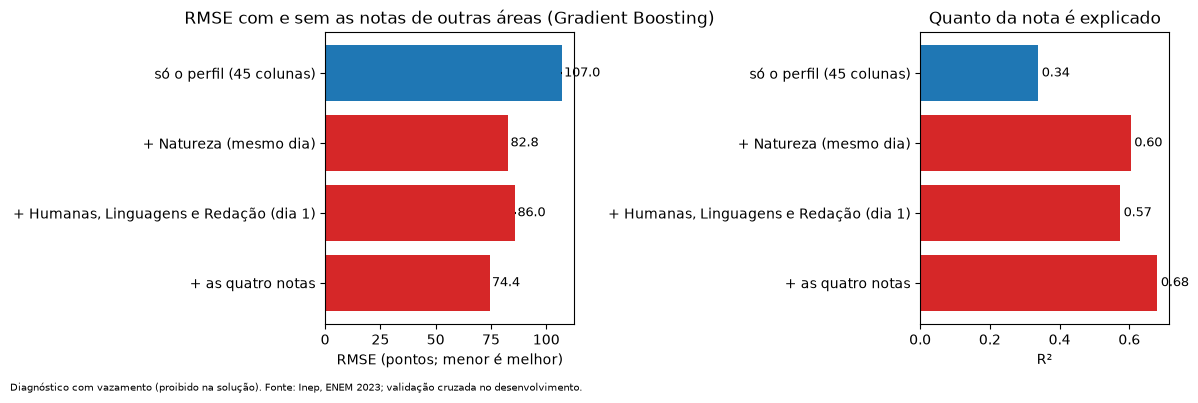

Com as quatro notas o RMSE cai de 107.0 para 74.4 e o R² sobe de 0.339 para 0.680.


In [6]:
gb = res[res["modelo"] == "Gradient Boosting"].set_index("entrada")
ref = gb.loc["só o perfil (45 colunas)", "RMSE"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(gb.index[::-1], gb["RMSE"][::-1], xerr=gb["RMSE_desvio"][::-1], color=["tab:red"] * 3 + ["tab:blue"])
ax[0].set_xlabel("RMSE (pontos; menor é melhor)")
ax[0].set_title("RMSE com e sem as notas de outras áreas (Gradient Boosting)")
for i, v in enumerate(gb["RMSE"][::-1]):
    ax[0].text(v + 1, i, f"{v:.1f}", va="center", fontsize=9)
ax[1].barh(gb.index[::-1], gb["R2"][::-1], color=["tab:red"] * 3 + ["tab:blue"])
ax[1].set_xlabel("R²")
ax[1].set_title("Quanto da nota é explicado")
for i, v in enumerate(gb["R2"][::-1]):
    ax[1].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
fig.text(0.01, 0.01, "Diagnóstico com vazamento (proibido na solução). Fonte: Inep, ENEM 2023; validação cruzada no desenvolvimento.", fontsize=7)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "diagnostico_dataset6.png", dpi=150)
plt.show()
print(f"Com as quatro notas o RMSE cai de {ref:.1f} para {gb.loc['+ as quatro notas', 'RMSE']:.1f} e o R² sobe de {gb.loc['só o perfil (45 colunas)', 'R2']:.3f} para {gb.loc['+ as quatro notas', 'R2']:.3f}.")

## E sem as notas zero no treino? (dataset 6 + notas zero fora do treino)

As 13.300 pessoas com nota 0 em Matemática (0,62%) puxam o erro: no notebook 02 sem zeros elas eram responsáveis por 13,7% do erro ao quadrado. Com as notas de outras áreas, o modelo pode **reconhecer** quem zerou (quem foi eliminado costuma ter também as outras notas zeradas ou ausentes). Aqui as notas zero saem **só do treino de cada dobra**; a validação mantém todos os participantes, inclusive os zeros (regra do enunciado). O RMSE é dado para todos, só para quem não zerou e só para quem zerou.

In [7]:
z = bruto[em_dev].assign(MT=y.values)
zer = z[z.MT == 0]
print(f"Pessoas com nota 0 em Matemática no desenvolvimento: {len(zer):,}")
for c in NOTAS:
    print(f"  {c.replace('NU_NOTA_', ''):<8} ausente: {zer[c].isna().mean():6.1%} | zero: {(zer[c] == 0).mean():6.1%} | média (de quem tem nota): {zer[c].mean():6.1f}   [quem não zerou: média {z.loc[z.MT > 0, c].mean():.1f}]")

Pessoas com nota 0 em Matemática no desenvolvimento: 13,300
  CN       ausente:   0.0% | zero:  98.3% | média (de quem tem nota):    7.2   [quem não zerou: média 498.8]
  CH       ausente:   2.1% | zero:   1.1% | média (de quem tem nota):  474.0   [quem não zerou: média 526.5]
  LC       ausente:   2.1% | zero:   0.3% | média (de quem tem nota):  481.3   [quem não zerou: média 520.5]
  REDACAO  ausente:   2.1% | zero:  17.3% | média (de quem tem nota):  449.5   [quem não zerou: média 627.7]


In [8]:
def cv_zeros(modelo, cols, tirar_zeros):
    linhas = []
    for tr, va in dobras.split():
        tr = tr[(y.iloc[tr].to_numpy() > 0)] if tirar_zeros else tr          # zeros saem só do treino da dobra
        m = clone(modelo).fit(X6.iloc[tr][cols], y.iloc[tr])
        p = m.predict(X6.iloc[va][cols]); yv = y.iloc[va].to_numpy(); nz = yv > 0
        linhas.append(dict(RMSE=mean_squared_error(yv, p) ** 0.5, RMSE_sem_zeros=mean_squared_error(yv[nz], p[nz]) ** 0.5,
                           RMSE_zeros=mean_squared_error(yv[~nz], p[~nz]) ** 0.5, MAE=mean_absolute_error(yv, p), R2=r2_score(yv, p)))
    return pd.DataFrame(linhas)


lz = []
for nome in ["só o perfil (45 colunas)", "+ as quatro notas"]:
    for modelo_nome, modelo in [("Gradient Boosting", hgb()), ("Regressão linear", make_pipeline(StandardScaler(), LinearRegression()))]:
        for tirar in (False, True):
            d = cv_zeros(modelo, VARIANTES[nome], tirar)
            lz.append({"entrada": nome, "modelo": modelo_nome, "zeros no treino": "não" if tirar else "sim", "RMSE": d.RMSE.mean(), "RMSE_desvio": d.RMSE.std(),
                       "RMSE só quem não zerou": d.RMSE_sem_zeros.mean(), "RMSE dos zeros": d.RMSE_zeros.mean(), "R2": d.R2.mean()})
            print(f"{nome:<26} {modelo_nome:<18} zeros no treino: {'não' if tirar else 'sim'} | RMSE {d.RMSE.mean():7.3f} ± {d.RMSE.std():.3f} | sem zeros {d.RMSE_sem_zeros.mean():7.3f} | zeros {d.RMSE_zeros.mean():7.2f} | R² {d.R2.mean():.3f}", flush=True)
rz = pd.DataFrame(lz)
rz.to_csv(TAB / "diagnostico_dataset6_sem_zeros.csv", index=False)
rz.round(3)

só o perfil (45 colunas)   Gradient Boosting  zeros no treino: sim | RMSE 107.048 ± 0.196 | sem zeros  99.409 | zeros  515.05 | R² 0.339


só o perfil (45 colunas)   Gradient Boosting  zeros no treino: não | RMSE 107.121 ± 0.198 | sem zeros  99.358 | zeros  519.06 | R² 0.338


só o perfil (45 colunas)   Regressão linear   zeros no treino: sim | RMSE 110.378 ± 0.190 | sem zeros 102.815 | zeros  521.24 | R² 0.297


só o perfil (45 colunas)   Regressão linear   zeros no treino: não | RMSE 110.430 ± 0.198 | sem zeros 102.759 | zeros  524.78 | R² 0.296


+ as quatro notas          Gradient Boosting  zeros no treino: sim | RMSE  74.426 ± 0.032 | sem zeros  74.458 | zeros   69.03 | R² 0.680


+ as quatro notas          Gradient Boosting  zeros no treino: não | RMSE  82.810 ± 0.135 | sem zeros  74.297 | zeros  471.32 | R² 0.604


+ as quatro notas          Regressão linear   zeros no treino: sim | RMSE  79.632 ± 0.062 | sem zeros  78.326 | zeros  198.82 | R² 0.634


+ as quatro notas          Regressão linear   zeros no treino: não | RMSE  80.508 ± 0.038 | sem zeros  77.702 | zeros  279.10 | R² 0.626


,entrada,modelo,zeros no treino,RMSE,RMSE_desvio,RMSE só quem não zerou,RMSE dos zeros,R2
0,só o perfil (45 colunas),Gradient Boosting,sim,107.048,0.196,99.409,515.052,0.339
1,só o perfil (45 colunas),Gradient Boosting,não,107.121,0.198,99.358,519.063,0.338
2,só o perfil (45 colunas),Regressão linear,sim,110.378,0.190,102.815,521.245,0.297
3,só o perfil (45 colunas),Regressão linear,não,110.430,0.198,102.759,524.778,0.296
4,+ as quatro notas,Gradient Boosting,sim,74.426,0.032,74.458,69.035,0.680
5,+ as quatro notas,Gradient Boosting,não,82.810,0.135,74.297,471.318,0.604
6,+ as quatro notas,Regressão linear,sim,79.632,0.062,78.326,198.825,0.634
7,+ as quatro notas,Regressão linear,não,80.508,0.038,77.702,279.099,0.626


## Leitura

As notas de outras áreas descrevem **a própria prova**, e não o perfil: quem vai bem em Natureza costuma ir bem em Matemática (mesmo dia, mesmo esforço e mesmo ambiente de prova). Por isso o erro cai muito quando elas entram. Isso confirma o diagnóstico dos outros notebooks: o limite de R² ≈ 0,35 vem da **informação disponível**, e não do modelo. Mas elas **não podem ser usadas** na solução: o objetivo do projeto é estimar a nota pelo perfil, antes da prova, e usar a nota de outra área responderia uma pergunta diferente (e, para uso real, ela só existe depois da prova).